# Parkinson's Disease Voice Detection

## Screening support, not diagnosis

Voice measurements could provide a low-cost, non-invasive screening aid that helps identify people who may benefit from clinical follow-up. Recall matters in screening because missing a person with Parkinson's disease (PD) can delay further assessment. This notebook studies screening support only; it is **not a diagnostic tool** and must not replace a qualified clinician.

The Oxford dataset has repeated voice recordings for each person. A random split can place recordings from the same speaker in both training and test data, letting speaker identity leak between them. Later sections will demonstrate this risk; no model results are claimed here.

## Problem statement

Can voice measurements support screening for PD while evaluating people who were not used to train the model? The key methodological issue is that each person contributes about six recordings, so validation must account for speaker identity rather than treating every recording as independent.

## Roadmap

| Section | Planned content |
|---|---|
| Setup and audit | Reproducible setup and source-data checks |
| Data dictionary | Feature meanings and recording structure |
| EDA | Explore measured voice data |
| Speaker-identity leakage test | Test the speaker-identity leakage concern |
| Leakage quantified | Compare split strategies |
| Models in pipelines | Build preprocessing and model pipelines |
| Recall-first evaluation | Evaluate with emphasis on recall |
| Calibration | Assess predicted probabilities |
| Subject-level decision | Aggregate evidence by person |
| Explainability | Interpret model behavior |
| Error analysis | Review prediction errors |
| Telemonitoring side study | Consider a separate regression dataset |
| Limitations | Discuss study constraints |
| Demo | Present a screening-support demonstration |

## TL;DR (to be completed at the end)

TBD

## Data attribution

**Why this step:** Attribution and licensing belong with the data so readers can trace its source and reuse conditions.

The Oxford Parkinsons voice dataset is attributed to Little, McSharry, Hunter, Spielman and Ramig (2008). The Parkinsons Telemonitoring dataset is attributed to Tsanas et al. (2009, 2010). Both datasets are distributed via the UCI repository under CC BY 4.0.

## 1. Setup and audit: imports and reproducible plotting

**Why this step:** Recording versions and fixing a plot style make the analysis easier to reproduce and figures easier to compare.

In [1]:
# Import only packages used in this notebook section and report their versions.
import base64
import gzip
import hashlib
import io
import platform
import re
import urllib.error
import urllib.request
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"matplotlib: {matplotlib.__version__}")

Python: 3.14.6
pandas: 3.0.6
numpy: 2.5.4
scikit-learn: 1.9.1
matplotlib: 3.11.2


### Insight

The printed versions record the software environment used by this notebook. The fixed random-state variable is available to make later stochastic steps repeatable.

### Embedded Oxford data source

**Why this step:** Embedding a compressed copy makes the graded notebook usable without network access. The source bytes come directly from the repository's UCI Parkinsons (Oxford) CSV; the payload is integrity-checked against its SHA-256 digest before parsing. Source: UCI Parkinsons dataset, CC BY 4.0; citation: Little, McSharry, Hunter, Spielman and Ramig (2008).

In [2]:
# The compressed payload is generated directly from the source CSV bytes.
OXFORD_B64 = (
    "..."
)
OXFORD_SHA256 = "a36116c2deac07895b79ce97a2f99a1b3720ac4892995ff5c3b9ccb397ed2bc5"


### Insight

The embedded payload is generated from the source CSV and verified by SHA-256 when the loader uses it. This avoids requiring a download for the primary analysis.

### Loader configuration and self-contained data access

**Why this step:** A local-first loader supports the project checkout, while the embedded payload provides an offline fallback. The optional Telemonitoring source is separate and is never required for Oxford detection.

In [3]:
# Keep data access inline so the notebook does not depend on src/ or write files.
FORCE_EMBEDDED = False
RANDOM_STATE = 42

OXFORD_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "parkinsons/parkinsons.data"
)
TELEMONITORING_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "parkinsons/telemonitoring/parkinsons_updrs.data"
)
OXFORD_DATASET_PAGE = "https://archive.ics.uci.edu/dataset/174/parkinsons"


def _local_data_paths(filename):
    # Check the documented paths relative to the notebook execution directory.
    return (Path("../data/raw") / filename, Path("data/raw") / filename)


def load_oxford(force_embedded=False):
    # Prefer a supplied local dataset unless the offline payload is explicitly forced.
    if not force_embedded:
        for candidate in _local_data_paths("parkinsons.data"):
            if candidate.is_file():
                print(f"Oxford source: local file ({candidate})")
                return pd.read_csv(candidate)

    # Verify the compressed bytes before decoding any CSV content.
    compressed = base64.b64decode(OXFORD_B64)
    csv_bytes = gzip.decompress(compressed)
    actual_sha256 = hashlib.sha256(csv_bytes).hexdigest()
    if actual_sha256 != OXFORD_SHA256:
        raise ValueError(
            "Embedded Oxford CSV failed SHA-256 verification: "
            f"expected {OXFORD_SHA256}, got {actual_sha256}."
        )
    csv_text = csv_bytes.decode("utf-8")
    print("Oxford source: embedded gzip/base64 payload (SHA-256 verified)")
    return pd.read_csv(io.StringIO(csv_text))


def load_telemonitoring():
    # Reuse a local copy when available; otherwise try UCI with TLS verification enabled.
    for candidate in _local_data_paths("parkinsons_updrs.data"):
        if candidate.is_file():
            print(f"Telemonitoring source: local file ({candidate})")
            return pd.read_csv(candidate)

    try:
        with urllib.request.urlopen(TELEMONITORING_URL, timeout=20) as response:
            csv_bytes = response.read()
        print("Telemonitoring source: UCI download (TLS verification enabled)")
        return pd.read_csv(io.BytesIO(csv_bytes))
    except (OSError, urllib.error.URLError, TimeoutError, pd.errors.ParserError) as error:
        print(
            "Warning: Telemonitoring could not be loaded; its side study will be skipped. "
            f"Details: {error}"
        )
        return None


# Parse subject and recording identifiers after loading the Oxford source.
oxford = load_oxford(force_embedded=FORCE_EMBEDDED)
oxford["subject_id"] = oxford["name"].str.extract(r"(S\d+)", expand=False)
oxford["recording_id"] = oxford["name"].str.extract(r"_(\d+)$", expand=False).astype("Int64")
telemonitoring = load_telemonitoring()

print(f"Oxford source shape: {oxford.shape}")
print(f"Telemonitoring available: {telemonitoring is not None}")

Oxford source: local file (..\data\raw\parkinsons.data)
Telemonitoring source: local file (..\data\raw\parkinsons_updrs.data)
Oxford source shape: (195, 26)
Telemonitoring available: True


### Insight

The printed source labels show whether Oxford data came from the checkout or the embedded payload. The parsed subject identifier groups recordings from the same person; the recording identifier retains the trailing recording number.

### Audit checks

**Why this step:** Explicit runtime checks stop analysis if the source file differs from the verified dataset, rather than allowing a changed input to pass silently.

In [4]:
# Validate the Oxford source and the optional regression-only Telemonitoring source.
expected_class_counts = {0: 48, 1: 147}
oxford_checks = [
    (len(oxford) == 195, f"Oxford row count must be 195; found {len(oxford)}."),
    (not oxford.isna().any().any(), "Oxford dataset contains null values."),
    (not oxford.duplicated().any(), "Oxford dataset contains duplicate rows."),
    (oxford["subject_id"].nunique() == 32,
     f"Oxford subject count must be 32; found {oxford['subject_id'].nunique()}."),
    (oxford["status"].isin([0, 1]).all(),
     "Oxford status must contain only 0 (healthy) and 1 (PD)."),
    (oxford.groupby("subject_id")["status"].nunique().le(1).all(),
     "Oxford status must be constant within each subject."),
    (oxford["status"].value_counts().to_dict() == expected_class_counts,
     "Oxford class counts must be 48 healthy (0) and 147 PD (1); "
     f"found {oxford['status'].value_counts().to_dict()}."),
]
for passed, message in oxford_checks:
    if not passed:
        raise ValueError(message)

# Check Telemonitoring only when it could be loaded; detection does not depend on it.
telemonitoring_checks = []
if telemonitoring is not None:
    telemonitoring_checks = [
        (len(telemonitoring) == 5875,
         f"Telemonitoring row count must be 5875; found {len(telemonitoring)}."),
        (telemonitoring["subject#"].nunique() == 42,
         "Telemonitoring subject count must be 42; "
         f"found {telemonitoring['subject#'].nunique()}."),
    ]
    for passed, message in telemonitoring_checks:
        if not passed:
            raise ValueError(message)

# Present an audit table from the checks that actually ran.
audit_rows = [
    ("Oxford row count", len(oxford), "PASS"),
    ("Oxford null values", int(oxford.isna().sum().sum()), "PASS"),
    ("Oxford duplicate rows", int(oxford.duplicated().sum()), "PASS"),
    ("Oxford subjects", int(oxford["subject_id"].nunique()), "PASS"),
    ("Oxford status values", sorted(oxford["status"].unique().tolist()), "PASS"),
    ("Oxford subject status consistency", "checked", "PASS"),
    ("Oxford status counts", oxford["status"].value_counts().sort_index().to_dict(), "PASS"),
]
if telemonitoring is not None:
    audit_rows.extend([
        ("Telemonitoring row count", len(telemonitoring), "PASS"),
        ("Telemonitoring subjects", int(telemonitoring["subject#"].nunique()), "PASS"),
    ])
audit_table = pd.DataFrame(audit_rows, columns=["Check", "Observed", "Result"])
display(audit_table)

,Check,Observed,Result
0,Oxford row count,195,PASS
1,Oxford null values,0,PASS
2,Oxford duplicate rows,0,PASS
3,Oxford subjects,32,PASS
4,Oxford status values,"[0, 1]",PASS
5,Oxford subject status consistency,checked,PASS
6,Oxford status counts,"{0: 48, 1: 147}",PASS
7,Telemonitoring row count,5875,PASS
8,Telemonitoring subjects,42,PASS


### Insight

The UCI page describes 31 people / 23 PD, while the supplied file verifies 32 subjects / 24 PD. This notebook trusts and validates the file's counts.

## 2. Data dictionary and data structure

**Why this step:** A plain-language dictionary makes the acoustic inputs interpretable before they are used in later analysis.

In [5]:
# Document the Oxford voice features and separate identifiers/target from predictors.
dictionary_rows = [
    ("MDVP:Fo(Hz)", "frequency", "average pitch"),
    ("MDVP:Fhi(Hz)", "frequency", "highest pitch"),
    ("MDVP:Flo(Hz)", "frequency", "lowest pitch"),
    ("MDVP:Jitter(%)", "jitter (cycle-to-cycle variation in pitch)", "cycle-to-cycle variation in pitch"),
    ("MDVP:Jitter(Abs)", "jitter (cycle-to-cycle variation in pitch)", "cycle-to-cycle variation in pitch"),
    ("MDVP:RAP", "jitter (cycle-to-cycle variation in pitch)", "cycle-to-cycle variation in pitch"),
    ("MDVP:PPQ", "jitter (cycle-to-cycle variation in pitch)", "cycle-to-cycle variation in pitch"),
    ("Jitter:DDP", "jitter (cycle-to-cycle variation in pitch)", "cycle-to-cycle variation in pitch"),
    ("MDVP:Shimmer", "shimmer (cycle-to-cycle variation in loudness)", "cycle-to-cycle variation in loudness"),
    ("MDVP:Shimmer(dB)", "shimmer (cycle-to-cycle variation in loudness)", "cycle-to-cycle variation in loudness"),
    ("Shimmer:APQ3", "shimmer (cycle-to-cycle variation in loudness)", "cycle-to-cycle variation in loudness"),
    ("Shimmer:APQ5", "shimmer (cycle-to-cycle variation in loudness)", "cycle-to-cycle variation in loudness"),
    ("MDVP:APQ", "shimmer (cycle-to-cycle variation in loudness)", "cycle-to-cycle variation in loudness"),
    ("Shimmer:DDA", "shimmer (cycle-to-cycle variation in loudness)", "cycle-to-cycle variation in loudness"),
    ("NHR", "noise", "noise-to-harmonics ratio"),
    ("HNR", "noise", "harmonics-to-noise ratio; higher = cleaner voice"),
    ("RPDE", "nonlinear", "nonlinear dynamical complexity"),
    ("DFA", "nonlinear", "signal fractal scaling exponent"),
    ("D2", "nonlinear", "nonlinear dynamical complexity"),
    ("spread1", "nonlinear", "nonlinear measure of variation in fundamental frequency"),
    ("spread2", "nonlinear", "nonlinear measure of variation in fundamental frequency"),
    ("PPE", "nonlinear", "nonlinear measure of variation in fundamental frequency"),
]
feature_dictionary = pd.DataFrame(
    dictionary_rows, columns=["Feature", "Family", "Plain-language meaning"]
)
non_feature_columns = pd.DataFrame(
    {"Non-feature columns": ["name", "subject_id", "recording_id", "status"]}
)
display(feature_dictionary)
display(non_feature_columns)

,Feature,Family,Plain-language meaning
0,MDVP:Fo(Hz),frequency,average pitch
1,MDVP:Fhi(Hz),frequency,highest pitch
2,MDVP:Flo(Hz),frequency,lowest pitch
3,MDVP:Jitter(%),jitter (cycle-to-cycle variation in pitch),cycle-to-cycle variation in pitch
4,MDVP:Jitter(Abs),jitter (cycle-to-cycle variation in pitch),cycle-to-cycle variation in pitch
5,MDVP:RAP,jitter (cycle-to-cycle variation in pitch),cycle-to-cycle variation in pitch
6,MDVP:PPQ,jitter (cycle-to-cycle variation in pitch),cycle-to-cycle variation in pitch
7,Jitter:DDP,jitter (cycle-to-cycle variation in pitch),cycle-to-cycle variation in pitch
8,MDVP:Shimmer,shimmer (cycle-to-cycle variation in loudness),cycle-to-cycle variation in loudness
9,MDVP:Shimmer(dB),shimmer (cycle-to-cycle variation in loudness),cycle-to-cycle variation in loudness


,Non-feature columns
0,name
1,subject_id
2,recording_id
3,status


### Insight

The dictionary separates measured voice features from identifiers and the status target. Subject and recording identifiers describe the sampling structure; they are not voice measurements.

### Recordings and class balance by analysis unit

**Why this step:** Multiple recordings from one speaker are correlated. Reporting balance at both the recording and subject level shows why the person, not an individual recording, is the meaningful unit for validation.

,subject_id,recordings,status
0,S01,6,1
1,S02,6,1
2,S04,6,1
3,S05,6,1
4,S06,6,1
5,S07,6,0
6,S08,6,1
7,S10,6,0
8,S13,6,0
9,S16,6,1


,recordings,subjects
status,,
Healthy (0),48,8
PD (1),147,24


Always-PD recording-level accuracy: 0.754
Always-PD subject-level accuracy: 0.750


Figure saved to ../reports/figures/02_data_structure.png


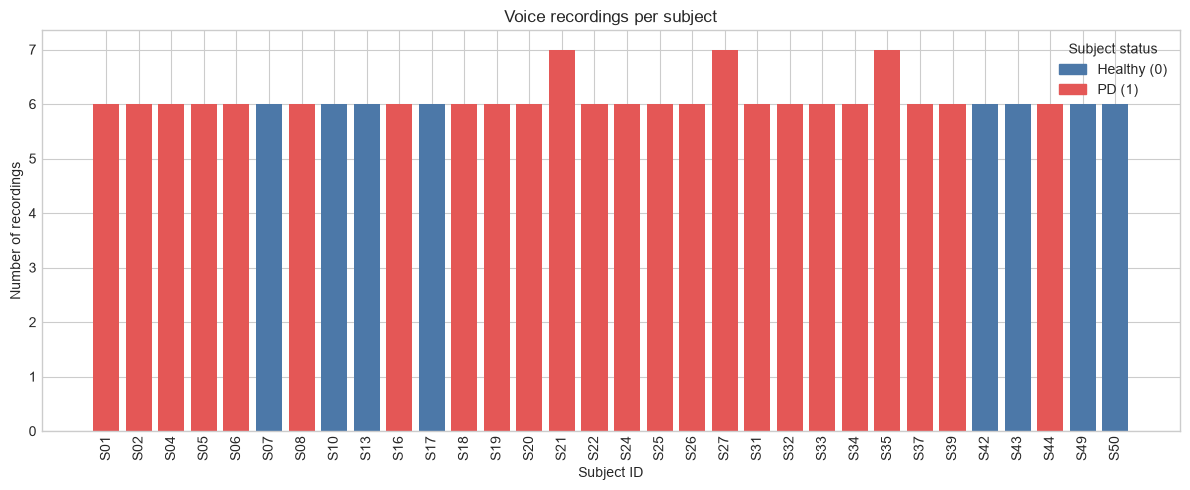

In [6]:
# Summarize recordings per speaker and verify status is available for coloring.
subject_summary = (
    oxford.groupby("subject_id", as_index=False)
    .agg(recordings=("name", "size"), status=("status", "first"))
    .sort_values("subject_id")
    .reset_index(drop=True)
)
display(subject_summary[["subject_id", "recordings", "status"]])

# Compute class balance from the loaded data, rather than typing results into the notebook.
recording_balance = oxford["status"].value_counts().sort_index().rename("recordings")
subject_balance = (
    subject_summary.groupby("status")["subject_id"].nunique().sort_index().rename("subjects")
)
class_balance = pd.concat([recording_balance, subject_balance], axis=1).fillna(0).astype(int)
class_balance.index = class_balance.index.map({0: "Healthy (0)", 1: "PD (1)"})
display(class_balance)

# An always-PD rule predicts the majority class at each unit of analysis.
recording_accuracy = float((oxford["status"] == 1).mean())
subject_accuracy = float((subject_summary["status"] == 1).mean())
print(f"Always-PD recording-level accuracy: {recording_accuracy:.3f}")
print(f"Always-PD subject-level accuracy: {subject_accuracy:.3f}")

# Color each speaker by their subject-level label to make the repeated-recording structure visible.
status_colors = subject_summary["status"].map({0: "#4C78A8", 1: "#E45756"})
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(subject_summary["subject_id"], subject_summary["recordings"], color=status_colors)
ax.set_title("Voice recordings per subject")
ax.set_xlabel("Subject ID")
ax.set_ylabel("Number of recordings")
ax.tick_params(axis="x", rotation=90)
legend_handles = [
    matplotlib.patches.Patch(color="#4C78A8", label="Healthy (0)"),
    matplotlib.patches.Patch(color="#E45756", label="PD (1)"),
]
ax.legend(handles=legend_handles, title="Subject status")
fig.tight_layout()

# Keep the notebook runnable when the optional report folder is absent or read-only.
try:
    fig.savefig(Path("../reports/figures/02_data_structure.png"), dpi=150)
    print("Figure saved to ../reports/figures/02_data_structure.png")
except OSError as error:
    print(f"Figure was not saved: {error}")
plt.show()

### Insight

Accuracy alone can conceal missed healthy subjects or the repeated-recording structure: an always-PD baseline provides context but is not a sufficient evaluation. Recordings from one person are not independent, so the subject must be the unit for validation and subject-grouped splits are needed.